In [12]:
import numpy as np

# --- parameters ---
N = 32                # number of neurons
eta = 0.01           # learning rate
alpha = 0.001        # decay on weights
tau = 1              # lag in timesteps
T = 5000             # simulation duration

# random input activity over time (or you can plug in your own rates)
rates = np.random.randn(T + tau, N) * 0.5

# initialize weight matrix
W = np.random.randn(N, N) * 0.1

Wa = np.zeros((T, N, N))
Ws = np.zeros((T, N, N))
# --- learning loop ---
for t in range(T):
    r_t = rates[t]          # shape (N,)
    r_tau = rates[t + tau]  # shape (N,)

    # outer products give local pre-post products for all synapses
    term1 = np.outer(r_t, r_tau)   # r_i(t) * r_j(t+tau)
    term2 = np.outer(r_tau, r_t)   # r_j(t) * r_i(t+tau)

    dW = eta * (term1 - term2) - alpha * W
    Ws[t] = (W + W.T)
    Wa[t] = (W - W.T)
    W += dW

# --- check resulting skew-symmetry ---
sym_part = W + W.T
print("Symmetric part RMS:", np.sqrt(np.mean(sym_part**2)))
print("Final W:")
print(W)


Symmetric part RMS: 0.0009702813070566304
Final W:
[[-9.34783683e-04 -1.16146190e-01 -6.46350615e-02 ... -2.82750296e-02
  -1.24581353e-01 -6.85517136e-02]
 [ 1.15284008e-01  2.44202492e-04 -1.04587110e-01 ... -4.19301107e-02
   1.04619268e-01  2.14484814e-01]
 [ 6.51539759e-02  1.05588030e-01 -1.05136545e-03 ...  2.96142916e-02
  -1.11991328e-02 -9.18737469e-03]
 ...
 [ 2.78109897e-02  4.02622004e-02 -2.89313800e-02 ... -1.83357689e-03
  -4.36657312e-02  3.46601130e-03]
 [ 1.25021900e-01 -1.05515917e-01  1.22024150e-02 ...  4.47187675e-02
   1.23792073e-03 -1.64605533e-02]
 [ 7.03333273e-02 -2.14053429e-01  9.65668448e-03 ... -3.93381063e-03
   1.80749693e-02 -1.58257507e-04]]


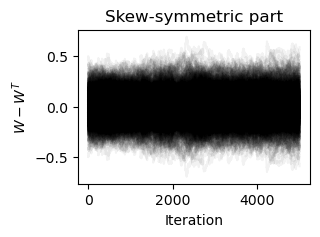

In [21]:
import matplotlib.pyplot as plt
plt.figure(figsize = (3,2))
plt.plot(np.arange(T), Wa.reshape(T, -1), "-k", alpha = 0.05);
plt.ylabel("$W - W^T$")
plt.title("Skew-symmetric part")
plt.xlabel("Iteration") 
plt.savefig("./figures/learning_rule_skew_symmetric", dpi=300, bbox_inches='tight')

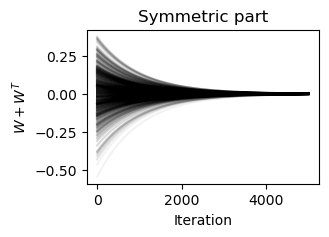

In [22]:
plt.figure(figsize = (3,2))

plt.plot(np.arange(T), Ws.reshape(T, -1), "-k", alpha = 0.05);
plt.ylabel("$W + W^T$")
plt.title("Symmetric part")
plt.xlabel("Iteration") 
plt.savefig("./figures/learning_rule_symmetric", dpi=300, bbox_inches='tight')